In [1]:
%pip install -r requirements-offline.txt --quiet

/Users/utarn/projects/datascience-metrology/.check-env/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


# Exercise — Module M6: พยากรณ์อย่างง่าย

**วิธีทำ:** เติมช่อง `# TODO` / `...` ให้ทุกเซลล์รันผ่าน แล้วตอบคำถาม markdown ที่กำหนด —
เปิด `book.ipynb` เทียบได้ตลอด (โค้ดชุดเดียวกัน แค่มีคำอธิบายมากกว่า)

**ข้อมูล (citation):** NOAA GML doi:10.15138/9N0H-ZH07 · Box & Jenkins (1976)
ผ่าน Rdatasets · กระทรวงการท่องเที่ยวและกีฬา (CC BY) · กรมควบคุมมลพิษ
(Open Data Common)

In [2]:
import numpy as np  # noqa: E402
import pandas as pd
from pathlib import Path


def repo_root() -> Path:
    """หา repo root โดยไล่ขึ้นจาก cwd."""
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "requirements-offline.txt").exists():
            return p
    raise SystemExit(
        "ไม่พบ repo root — เปิด JupyterLab จาก repo root (uv run jupyter lab)")

DATA = repo_root() / "datasets"

co2 = pd.read_csv(DATA / "noaa_co2" / "co2_mm_gl.csv", skiprows=38)
co2["date"] = pd.to_datetime(
    dict(year=co2["year"], month=co2["month"], day=1))
import matplotlib.pyplot as plt  # noqa: E402
plt.rcParams["font.family"] = [
    "DejaVu Sans", "Noto Sans Thai", "Leelawadee UI", "Tahoma",
]


## ส่วนที่ 1 — moving average และ trend line (CO2)

KeyError: 'ma12'

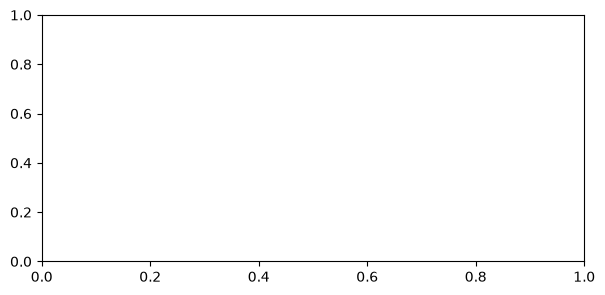

In [3]:
# TODO: คำนวณ moving average 24 เดือน เก็บในคอลัมน์ ma24
co2["ma24"] = ...

# วาดเทียบกับ ma12 จาก book — เส้นไหนเรียบกว่า?
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(co2["date"], co2["ma12"], color="#2a9d8f", lw=1.6,
        label="MA 12 เดือน")
ax.plot(co2["date"], co2["ma24"], color="#e63946", lw=1.6,
        label="MA 24 เดือน")
ax.legend()
ax.set_ylabel("CO2 (ppm)")
plt.show()

**คำถาม 1.1** moving average ยิ่งกว้าง (24 แทน 12) ยิ่งเรียบ —
แต่มัน**ช้ากว่าของจริง**ด้วย เห็นจากอะไรในกราฟ และเหมาะกับการใช้เมื่อไหร่?

In [4]:
# TODO: fit trend line จากทั้งชุด (x = decimal year อยู่แล้ว)
# แล้ว print ความชัน — หน่วย ppm ต่อปี
slope, intercept = ...
print(f"CO2 ขึ้นเฉลี่ยปีละ {slope:.2f} ppm")

TypeError: cannot unpack non-iterable ellipsis object

**คำถาม 1.2** ตัวเลขความชันนี้ ถ้าพูดกับผู้บริหารโรงงาน —
จะแปลเป็นประโยคภาษาคนอย่างไร (ห้ามพูดคำว่า "slope")?

## ส่วนที่ 2 — กับดัก extrapolation (นักท่องเที่ยว)

In [5]:
tour = pd.read_csv(
    DATA / "tourist_arrivals" / "tourist_arrivals_by_country.csv")
yearly = tour.groupby("year")["tourist_number"].sum()
history = yearly.loc[2015:2019]

m, b = np.polyfit(history.index, history, 1)
future = np.array([2020, 2021, 2022, 2023])
forecast = np.polyval([m, b], future)
print("เส้นตรงทำนายปี 2020-2023 (ล้านคน):")
for yr, fc in zip(future, forecast):
    actual = yearly[yr] / 1e6
    print(f"  {yr}: ทำนาย {fc / 1e6:.1f} · ของจริง {actual:.1f}")

# TODO: คำนวณ MAE ของการพยากรณ์นี้เทียบของจริง (หน่วย: ล้านคน)
mae = ...
print(f"พลาดเฉลี่ย {mae:.1f} ล้านคน/ปี")

เส้นตรงทำนายปี 2020-2023 (ล้านคน):
  2020: ทำนาย 42.3 · ของจริง 7.3
  2021: ทำนาย 44.7 · ของจริง 0.4
  2022: ทำนาย 47.2 · ของจริง 11.2
  2023: ทำนาย 49.6 · ของจริง 6.5


TypeError: unsupported format string passed to ellipsis.__format__

**คำถาม 2.1** ถ้ามีคนถามคุณว่า "ปี 2569 (ค.ศ. 2026) นักท่องเที่ยวจะกี่ล้าน" —
จะใช้เส้นตรงจาก 2015–2019 ตอบได้ไหม ตอบพร้อมเหตุผลสองประโยค

## ส่วนที่ 3 — วงรอบ (AirPassengers)

/tmp/ipykernel_33566/1891777828.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


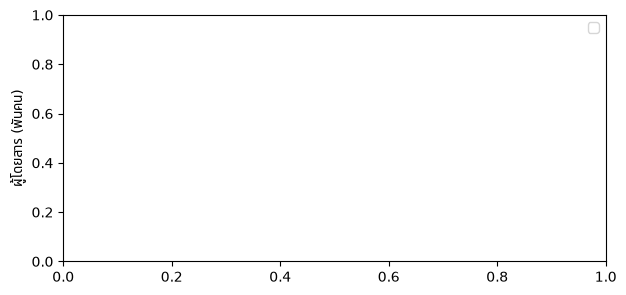

In [6]:
air = pd.read_csv(DATA / "air_passengers" / "AirPassengers.csv")
air["month"] = pd.date_range("1949-01", periods=len(air), freq="MS")
air["naive"] = air["value"].shift(12)
test = air.iloc[12:]

# TODO: วาดเส้นของจริง (value) กับเส้นทำนาย (naive) ของช่วง test
# ให้เส้นของจริงสี "#457b9d" และเส้นทำนายประสีแดง linestyle="--"
fig, ax = plt.subplots(figsize=(7, 3.2))
...
ax.legend()
ax.set_ylabel("ผู้โดยสาร (พันคน)")
plt.show()

**คำถาม 3.1** ช่วงเวลาไหนที่เส้นทำนาย "ตามหลัง" ของจริงชัดที่สุด —
และสิ่งนี้บอกอะไรเรื่องการเติบโตของยอดผู้โดยสาร?

## ส่วนที่ 4 — PM2.5 (moving average กว้างขึ้น)

KeyError: 'ma7'

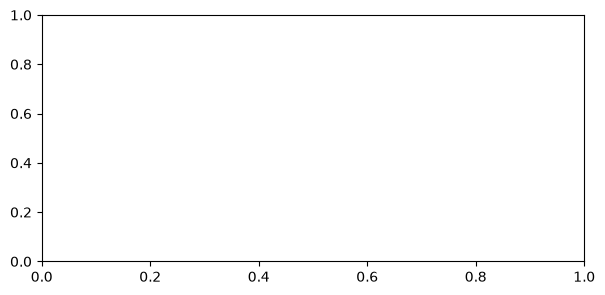

In [7]:
pm25 = pd.read_csv(DATA / "pcd_pm25_2025"
                   / "pm25_daily_2025_15stations.csv")
bkk = pm25[pm25["station_code"] == "02T"].copy()
bkk["date"] = pd.to_datetime(bkk["observation_date"])

# TODO: คำนวณ moving average 30 วัน เก็บในคอลัมน์ ma30
bkk["ma30"] = ...

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(bkk["date"], bkk["ma7"], color="#e63946", lw=1.6,
        label="MA 7 วัน")
ax.plot(bkk["date"], bkk["ma30"], color="#457b9d", lw=1.6,
        label="MA 30 วัน")
ax.legend()
ax.set_ylabel("PM2.5 (µg/m³)")
plt.show()

**คำถาม 4.1** เส้น 30 วันเรียบกว่า 7 วันชัด — แต่เห็นอะไร**น้อยลง**?
ถ้าเป้าหมายคือ "เตือนภัยวันที่ค่าพุ่งเร็ว" ควรใช้ MA กี่วัน และทำไม?